# Assignement 3
**Hypothesis Testing and Statistical Analysis**



**Group members:** <br>
- Paula Makowe <br>
- Suzan Mohammad <br>
- Chelsea Osei Owusu <br>

**Used Datasets:**
- Student Performance Dataset (nr. 2)
- Health & Lifestyle Sleep Study (nr. 4)

This notebook presents two independent statistical analyses based on the provided datasets.
Each analysis addresses a distinct research question and employs a different type of
statistical test, following a complete hypothesis-testing pipeline.

**Setting up Python Libraries**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import seaborn as sns
sns.set_theme(style='white')
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
import warnings 
warnings.simplefilter('ignore', category=FutureWarning)

## Empirical Analyses

### Study 1: Gender Differences in Mathematics Performance
Student Performance Dataset


**importing the Data**

In [3]:
student_performance = pd.read_csv("student_performance_merged.csv")
display(student_performance)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,G1_mat,G2_mat,G3_mat,failures_por,paid_por,absences_por,G1_por,G2_por,G3_por,ID
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,5,6,6,0,no,4,0,11,11,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,5,6,0,no,2,9,11,11,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,7,8,10,0,no,6,12,13,12,3
3,GP,F,15,U,GT3,T,4,2,health,services,...,15,14,15,0,no,0,14,14,14,4
4,GP,F,16,U,GT3,T,3,3,other,other,...,6,10,10,0,no,0,11,13,13,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
365,MS,F,19,R,GT3,T,2,3,services,other,...,7,5,0,1,no,4,10,11,10,366
366,MS,F,18,U,LE3,T,3,1,teacher,services,...,7,9,8,0,no,4,15,15,16,367
367,MS,F,18,U,GT3,T,1,1,other,other,...,6,5,0,0,no,6,11,12,9,368
368,MS,M,17,U,LE3,T,3,1,services,services,...,14,16,16,0,no,6,10,10,10,369


## Research Question

### Is there a difference in final mathematics performance (G3) between male and female students?

##### Why this question is interesting

Gender differences in academic performance are frequently discussed in educational research and policy. Understanding whether such differences exist in mathematics achievement can inform educational support strategies and challenge or confirm common assumptions.

##### Variables

Independent variable: sex (male vs. female; categorical, two independent groups)
Dependent variable: final math grade (G3; continuous)

## Hypothesis Formulation

##### Null Hypothesis (H₀)

There is no difference in mean final mathematics grades (G3) between male and female students.<br>
H₀: μmale = μfemale

##### Alternative Hypothesis (H₁)

There is a difference in mean final mathematics grades (G3) between male and female students.
H₁: μmale ≠ μfemale

##### Test Direction

A two-sided test is used because, although gender differences in academic performance are frequently discussed in educational research, there is no consistent theoretical or empirical consensus that one gender systematically outperforms the other in mathematics. Therefore, deviations in both directions are considered plausible.

##### Intended Test Type

An independent two-sample t-test is intended to compare the mean final mathematics grades between male and female students. If the assumptions of normality or homogeneity of variances are violated, a permutation test will be used as a non-parametric alternative.

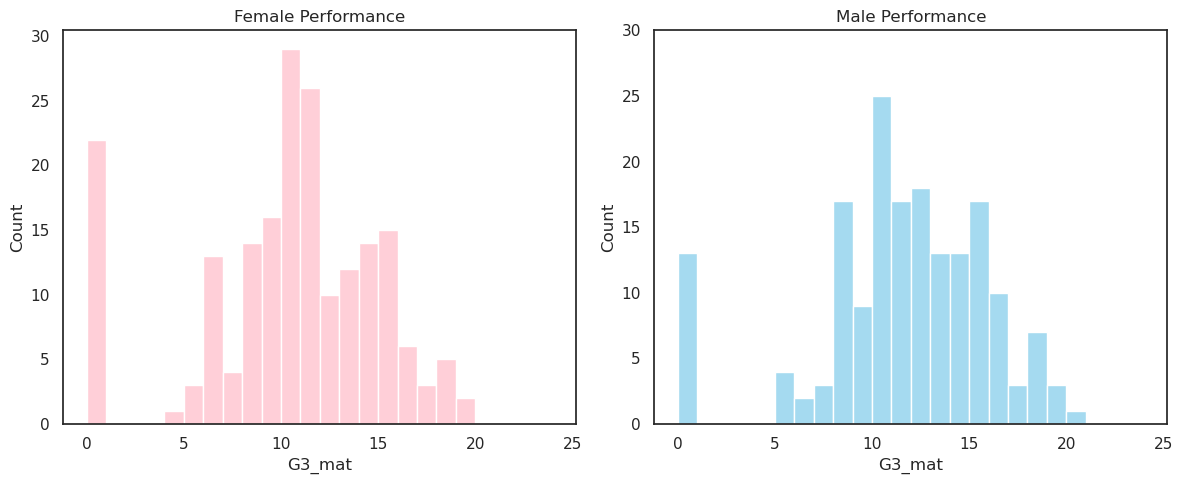

In [4]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(data=student_performance.query('sex == "F"'), x= 'G3_mat', color= 'pink', bins= range(0,25,1))
plt.title('Female Performance')

plt.subplot(1,2,2)
sns.histplot(data=student_performance.query('sex == "M"'), x= 'G3_mat', color= 'skyblue', bins= range(0,25,1))
plt.title('Male Performance')
plt.ylim(0,30)

plt.tight_layout()
plt.show()

Since the data is not really normal distributed, but bimodal especially for the females it is a safer option to use the unpaired permutation test for our research question.

## A prior Power Analysis

An a priori power analysis was conducted to determine the minimum sample size required to detect a difference in the performance of Portuguese male and female students with adequate statistical power.

#### Effect Size Assumption

A medium effect size of d = 0.5 was assumed. <br>

#### Justification:

A medium effect size (Cohen’s d = 0.5) was assumed for the a priori power analysis. This choice reflects typical effect sizes observed in educational and behavioral research and fits the substantial overlap observed in the male and female G3 score distributions.

#### Statistical Parameters

Significance level: α = 0.05 <br>
Desired power: 1 − β = 0.80 <br>
Test type: difference in means of two independent groups 

In [6]:
from statsmodels.stats.power import TTestIndPower

# Assumed effect size (medium)
effect_size = 0.5

# Significance level and desired power
alpha = 0.05
power = 0.80

analysis = TTestIndPower()

# Sample size PER GROUP
n_per_group = analysis.solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)

n_total = n_per_group * 2

print(f"Required sample size per group: {n_per_group:.2f}")
print(f"Total required sample size: {n_total:.0f}")

Required sample size per group: 63.77
Total required sample size: 128


#### Result and Interpretation

The a priori power analysis indicates that a sample size of approximately 128 participants is required to detect a medium-sized effect (d = 0,5 ) between the G3_mat scores of the Portuguese male and female students with a statistical power of 0.80 at a significance level of α = 0.05 using a two-sided test.

This means that, assuming a realistic moderate association between the two variables, a study with at least 128 observations would have an 80% probability of detecting this effect if it truly exists in the population. This sample size serves as a benchmark for evaluating whether the available dataset is sufficiently powered to address the research question.

## Dataset Description

The present analysis uses the Student Performance dataset, which comprises achievement in secondary education at two Portuguese school from 649 students. It includes student grades in mathematics and Portuguese language courses, along with various demographic, social, and school-related attributes.

#### Sample Size

After data screening and cleaning, no observations were excluded.<br>
Therefore, the final sample size is N = 370.

This sample size exceeds the minimum required sample size of N ≈ 128 determined by the a priori power analysis. Consequently, the available dataset is more than sufficiently powered to detect the difference between the mathematics result of male and female students.

#### Variables of Interest

The present analysis focuses on the following variables:
- G3_mat: a continuous variable stated as an integer
- sex: a categorical variable with two possible categories in this dataset

In [5]:
student_performance.describe()

,age,Medu,Fedu,traveltime,studytime,failures_mat,famrel,freetime,goout,Dalc,...,absences_mat,G1_mat,G2_mat,G3_mat,failures_por,absences_por,G1_por,G2_por,G3_por,ID
count,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,...,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.00000
mean,16.575676,2.800000,2.556757,1.445946,2.043243,0.278378,3.935135,3.224324,3.116216,1.483784,...,5.381081,10.891892,10.751351,10.464865,0.132432,3.632432,12.135135,12.270270,12.554054,185.50000
std,1.180672,1.083505,1.086138,0.701178,0.847934,0.710599,0.911301,0.985506,1.128592,0.896247,...,7.665653,3.345375,3.800986,4.608830,0.489762,4.827656,2.552029,2.465465,2.943653,106.95404
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,1.00000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,...,0.000000,8.000000,9.000000,8.000000,0.000000,0.000000,10.000000,11.000000,11.000000,93.25000
50%,17.000000,3.000000,3.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,...,4.000000,11.000000,11.000000,11.000000,0.000000,2.000000,12.000000,12.000000,13.000000,185.50000
75%,17.000000,4.000000,3.750000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,...,8.000000,13.000000,13.000000,14.000000,0.000000,6.000000,14.000000,14.000000,14.000000,277.75000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,75.000000,19.000000,19.000000,20.000000,3.000000,32.000000,19.000000,19.000000,19.000000,370.00000


In [7]:
student_performance.groupby('sex')['G3_mat'].describe()

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
F,195.0,9.892308,4.676514,0.0,8.0,10.0,13.0,19.0
M,175.0,11.102857,4.459362,0.0,9.0,11.0,14.0,20.0


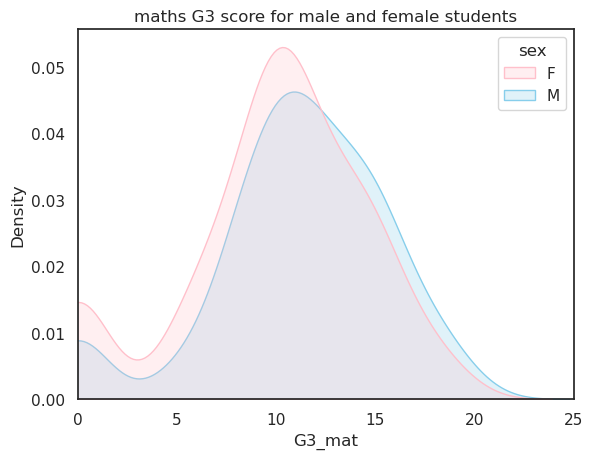

In [8]:
sns.kdeplot(student_performance, x='G3_mat', hue= ('sex'), fill= True, palette=['pink','skyblue'] )
plt.xlim(0,25)
plt.title('maths G3 score for male and female students')
plt.show()

#### Descriptive Statistics

The descriptive statistics indicates that male students on average score 11 and female students 10 with a standard deviation of 4,5 for the male and 4,7 for the female students.<br>
The interquartile range shows that 50% of the male students score between 9 and 14 and 50% of the female students score between 8 and 13. The highest score for the boys is 20 and for the girls 19. For both groups the lowest score are 0.

#### Additional Dataset Characteristics and Limitations

Additional variables in the dataset include school, age, address, the family size, the parent status, reason, guardian, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic, travel time, study time, failures, family relationship
quality, free time, going out, alcohol consumption, health,
absences, G1, G2 and G3 results for mathematics and Portuguese language. The sample includes the data of Portuguese students between the ages of 15 to 22 from two different schools.

With a sample size of 370 the dataset has a relatively good validity, but since the students all come from just two specific secondary schools in Portugal and are between a specific age range the results are not really transferable to all Portuguese schools or even to other countries. Also the data only includes the exam scores for the subjects Portuguese and mathematics excluding other subjects and other forms of performance.

## Data Cleaning

The data cleaning process was conducted in several steps to ensure data quality and suitability for the planned permutation test.

### Step 1: 
Initial Data Inspection
First, the dataset was inspected using summary statistics to identify potential irregularities, missing values, and implausible entries.

In [6]:
student_performance.describe()

,age,Medu,Fedu,traveltime,studytime,failures_mat,famrel,freetime,goout,Dalc,...,absences_mat,G1_mat,G2_mat,G3_mat,failures_por,absences_por,G1_por,G2_por,G3_por,ID
count,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,...,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.00000
mean,16.575676,2.800000,2.556757,1.445946,2.043243,0.278378,3.935135,3.224324,3.116216,1.483784,...,5.381081,10.891892,10.751351,10.464865,0.132432,3.632432,12.135135,12.270270,12.554054,185.50000
std,1.180672,1.083505,1.086138,0.701178,0.847934,0.710599,0.911301,0.985506,1.128592,0.896247,...,7.665653,3.345375,3.800986,4.608830,0.489762,4.827656,2.552029,2.465465,2.943653,106.95404
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,1.00000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,...,0.000000,8.000000,9.000000,8.000000,0.000000,0.000000,10.000000,11.000000,11.000000,93.25000
50%,17.000000,3.000000,3.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,...,4.000000,11.000000,11.000000,11.000000,0.000000,2.000000,12.000000,12.000000,13.000000,185.50000
75%,17.000000,4.000000,3.750000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,...,8.000000,13.000000,13.000000,14.000000,0.000000,6.000000,14.000000,14.000000,14.000000,277.75000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,75.000000,19.000000,19.000000,20.000000,3.000000,32.000000,19.000000,19.000000,19.000000,370.00000


The merged dataset initially contained N = 370 observations.

### Step 2: Missing Values

The inspection revealed no missing values for all variables, so no observations need to be excluded and no imputation procedures were applied.

In [10]:
student_performance.isna().sum()

school          0
sex             0
age             0
address         0
famsize         0
Pstatus         0
Medu            0
Fedu            0
Mjob            0
Fjob            0
reason          0
guardian        0
traveltime      0
studytime       0
failures_mat    0
schoolsup       0
famsup          0
paid_mat        0
activities      0
nursery         0
higher          0
internet        0
romantic        0
famrel          0
freetime        0
goout           0
Dalc            0
Walc            0
health          0
absences_mat    0
G1_mat          0
G2_mat          0
G3_mat          0
failures_por    0
paid_por        0
absences_por    0
G1_por          0
G2_por          0
G3_por          0
ID              0
dtype: int64

No observations were excluded due to missing values.

### Step 3: Inspection of Categorical Variables and Filler Values

Categorical variables were examined to identify potential filler values (e.g., “99”) or implausible entries.

In [11]:
student_performance.select_dtypes(include="object").describe()

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid_mat,activities,nursery,higher,internet,romantic,paid_por
count,370,370,370,370,370,370,370,370,370,370,370,370,370,370,370,370,370,370
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no,no
freq,331,195,289,266,332,134,205,135,266,321,231,196,191,298,354,313,251,345


No filler values or invalid categories were detected in the categorical variables. Therefore, no recoding or exclusion was necessary.

### Step 4: Duplicate Observations

The dataset was checked for duplicate rows.

In [12]:
student_performance.duplicated().sum()

0

No duplicate observations were found.

### Step 5: Outlier Assessment

The G3 mathematics score for male and female students were inspected using descriptive statistics. All observed values fell within plausible ranges for the exam scores between 0 and 20..

In [14]:
student_performance.groupby('sex')['G3_mat'].describe()

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
F,195.0,9.892308,4.676514,0.0,8.0,10.0,13.0,19.0
M,175.0,11.102857,4.459362,0.0,9.0,11.0,14.0,20.0


No observations were classified as outliers. Therefore, no exclusions were applied.

### Step 6: Conclusion of Data Cleaning

##### Final Sample Size and report

In conclusion, the data cleaning process for Study 1 confirmed that the dataset was suitable for the planned analysis without requiring exclusions or transformations.<br>

No missing values were present in the variables of interest, and therefore no observations were removed at this stage. Visual inspection of the final mathematics grade (G3) indicated that all observed values fell within the theoretically valid range of the grading scale and represented meaningful academic outcomes. Consequently, no outliers were excluded. <br>

As no data transformations or exclusions were applied, the sample size remained unchanged from N = 370 before cleaning to N = 370 after cleaning, ensuring that the full dataset could be used for the subsequent statistical analyses.

## Descriptive Statistics & Visualization

The descriptive statistics and visualizations provide an overview of the distributions of the scores for the G3 in mathematics for the male and female students in the dataset. <br>
This step helps understand the data before performing the following analysis.

In [15]:
student_performance.groupby('sex')['G3_mat'].describe()

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
F,195.0,9.892308,4.676514,0.0,8.0,10.0,13.0,19.0
M,175.0,11.102857,4.459362,0.0,9.0,11.0,14.0,20.0


##### Interpretation:

The scores of both the male and female Portuguese students is approximately normally distributed (excluding the lower scores) but because also quit a few students scored 0, they have another peak at 0 and are bimodal. Both groups results are quite distributed with a standard deviation with 4,5 for the males and 4,7 for the females.

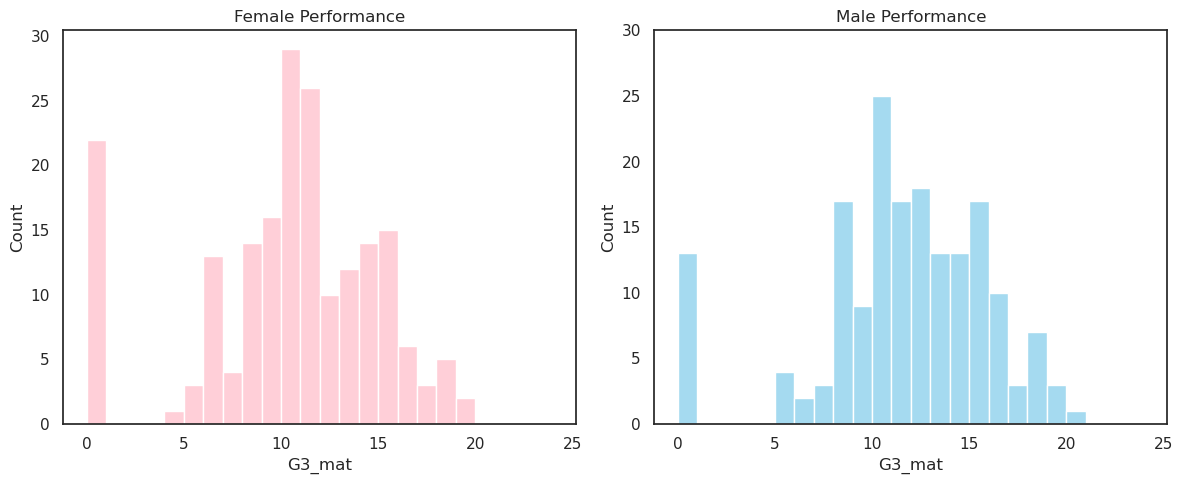

In [16]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(data=student_performance.query('sex == "F"'), x= 'G3_mat', color= 'pink', bins= range(0,25,1))
plt.title('Female Performance')

plt.subplot(1,2,2)
sns.histplot(data=student_performance.query('sex == "M"'), x= 'G3_mat', color= 'skyblue', bins= range(0,25,1))
plt.title('Male Performance')
plt.ylim(0,30)

plt.tight_layout()
plt.show()

The descriptive statistics and histogram show that most students, both female and male, have grades between about 8 and 15. The biggest number of students score around 10 to 12 points.
There are some male and female students with very low score, which shows in another peak at 0. The shapes of the two histoplots look very similar. They both have one main peak in the middle around 10 points and then fewer students with very low or very high grades.

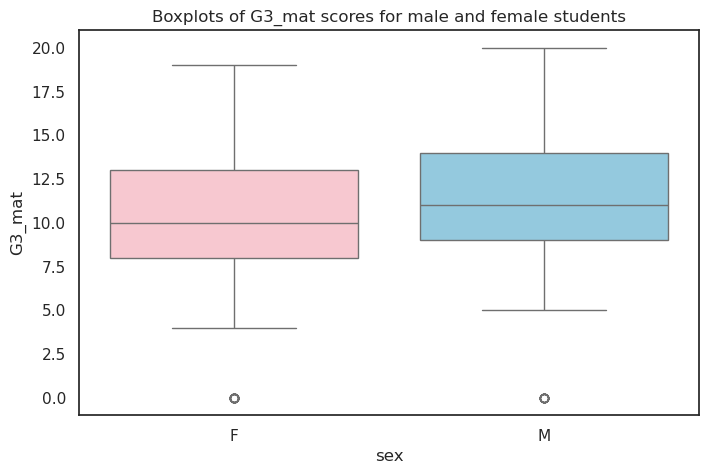

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(data=student_performance, x= 'sex', y= 'G3_mat', palette=['pink','skyblue'])
plt.title('Boxplots of G3_mat scores for male and female students')
plt.show()

The boxplot shows the distributions of the G3 mathematics scores separated for female and male students.

For female students, the median is around 10 points. Most female students have grades between about 8 and 13. Some girls have very low grades, even 0, which are shown as outliers and some have high grades up to around 19.

For male students, the median is slightly higher, around 11 points. Most male students have grades between about 9 and 14. They also have some students with 0, which are also shown as outliers and some with high grades up to about 20.

The boxes for males and females are very similar in size and position.

### Conclusion

Overall the descriptive statistics and visualizations reveal clear patterns in the mathematics grades of male and female students. The G3_mat scores for both groups are mainly concentrated between about 8 and 15 points, with a peak around 10 to 12 points. Both distributions show some very low values, including zeros and some high scores, indicating a moderate spread of performance in both groups. The histograms show strong overlap between males and females, suggesting that their grade distributions are very similar.

The boxplots confirm this pattern. Both groups have similar ranges and variability, and although the median score for male students is slightly higher than for female students, the difference is small. There is no strong separation between the two groups, and both show a comparable number of low and high performers.

Together, these observations suggest that male and female students have broadly similar mathematics outcomes, with only a small difference in the central. This supports the use of a statistical test, such as a permutation test of the difference in means, to formally evaluate whether the observed difference is larger than what would be expected by random variation alone.

## Assumption Checks & Test Selection

The following plots were already presented and analyzed in the Descriptive Statistics and Visualization section. They are shown again here to justify the choice of statistical test.

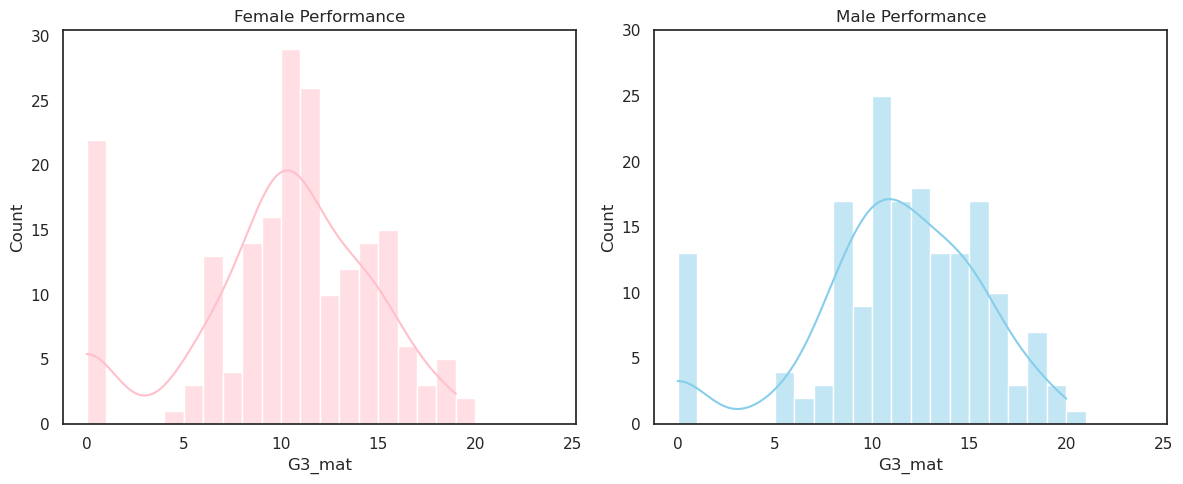

In [19]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(data=student_performance.query('sex == "F"'), x= 'G3_mat', color= 'pink', bins= range(0,25,1), kde= True)
plt.title('Female Performance')

plt.subplot(1,2,2)
sns.histplot(data=student_performance.query('sex == "M"'), x= 'G3_mat', color= 'skyblue', bins= range(0,25,1), kde= True)
plt.title('Male Performance')
plt.ylim(0,30)

plt.tight_layout()
plt.show()

The histograms of G3_mat scores for male and female students show that both groups have very similar distribution shapes. In both groups most scores lay between about 8 and 15 points with a peak around 10 to 12. Both distributions also contain some very low values including zeros and a small number of high scores, which indicates slight skewness and the presence of outliers. Because of this the data is not perfectly normal distribution.

However the two histograms overlap strongly and have comparable spread, shape, and central tendency. This means that under the null hypothesis of no difference between males and females, the group labels can reasonably be considered exchangeable.

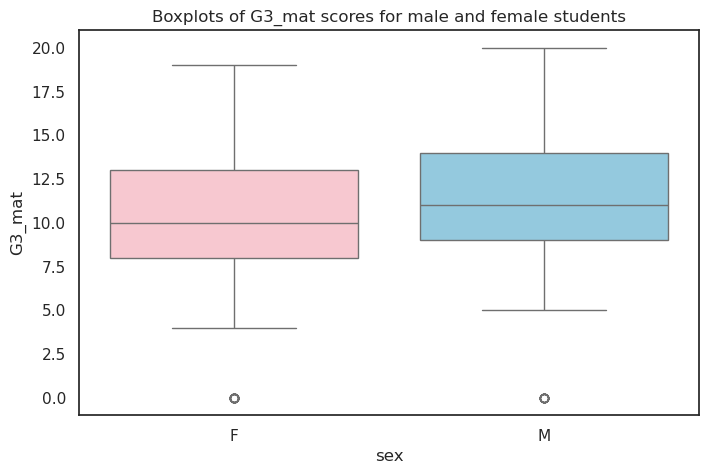

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(data=student_performance, x= 'sex', y= 'G3_mat', palette=['pink','skyblue'])
plt.title('Boxplots of G3_mat scores for male and female students')
plt.show()

The boxplots show that the G3_mat scores for male and female students have very similar medians, ranges, and overall spread. Both groups contain outliers at low values, including zeros and high values at the top of the scale, indicating that the data are not perfectly normally distributed. However, the strong overlap between the two boxplots and their similar variability suggest that the two groups come from comparable distributions.


### Step 1: Assumption Checking

- Histograms show that both male and female distributions have similar shapes, peaks between 10–12, 
  and comparable spreads.
- Boxplots indicate similar medians, ranges, and overall variability for both groups.
- Some low (including zeros) and high values indicate slight skewness and the presence of outliers.
- Despite slight non-normality and a few outliers, the strong overlap supports the assumption of 
  exchangeability under the null hypothesis (no difference between groups).

### Step 2: Test Selection

- Decision: A permutation test of the difference in means is appropriate.


### Step 3: Justification

- Permutation tests do not assume normality, making them robust to slight skewness and outliers.
- The assumption of exchangeable group labels under the null hypothesis is supported by the 
  visual similarity of the distributions.
- Therefore, the test provides a valid and reliable estimate of whether the observed difference 
  in means is significant.

### Conclusion
After Visual inspection of the male and female G3 score distributions both show similar shapes, spreads and the presence of zero values. 
This supports the assumption of exchangeability under the null hypothesis, making a permutation test of the difference in means appropriate. 
Because permutation tests do not rely on the data being normal distributed, the observed skewness does not invalidate the analysis.

## Statistical Tests

A permutation test for the difference in means of the two independent groups male and female students was chosen as the following performing statistical test.

In [21]:
# mean difference for g3_mat for male and females

student_performance.query('sex == "M"').G3_mat.mean() - student_performance.query('sex == "F"').G3_mat.mean()

1.2105494505494505

In [22]:
#run 10,000 shuffles

def dMeans(x, y):
    return np.mean(x)-np.mean(y)

results = stats.permutation_test((student_performance.query('sex == "M"').G3_mat, student_performance.query('sex == "F"').G3_mat), dMeans, 
                                  permutation_type='independent', alternative='two-sided', n_resamples=10000)
print(results)

PermutationTestResult(statistic=1.2105494505494505, pvalue=0.0105989401059894, null_distribution=array([ 0.3214652 , -0.37245421,  0.11545788, ..., -0.53509158,
       -0.3832967 , -0.68688645]))


#### Description of the code:

The choosen permutation test for independent sample randomly shuffles the individual G3_mat scores and assignes them randomly to the groups male/female.

- mean difference: the test statistic (mean difference) from our actual data, which is 1.2
- p value: the proportion of shuffles in which a result greater than 1.2 was obtained (due to chance), which is 0.006
- null distribution: contains all 10,000 difference of mean values, for the 10,000 shuffles

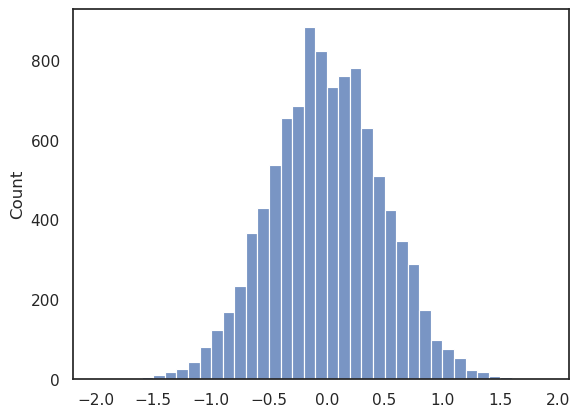

In [23]:
# plot the null distribution in a histogram

sns.histplot(results.null_distribution, bins=np.arange(-2,2,0.1))
plt.show()

## Results


An independent sample permutation test was conducted to examine differences in final mathematics grades (G3) between male and female Portuguese students. The results are as follows:

- Mean difference (Males − Females): 1.21
- Number of permutations: 10,000
- Two-sided p-value: 0.0104

Since p < 0.05, we reject the null hypothesis that there is no difference in mean final mathematics grades between male and female students.

To quantify the effect size, Cohen’s d was calculated:

In [24]:
# calculate Cohen's d

# calculate shared standard deviation s

xM = student_performance.query('sex=="M"').G3_mat.mean()
xF = student_performance.query('sex=="F"').G3_mat.mean()

sM = student_performance.query('sex=="M"').G3_mat.std()
sF = student_performance.query('sex=="F"').G3_mat.std()

nM = student_performance.query('sex=="M"').G3_mat.count()
nF = student_performance.query('sex=="F"').G3_mat.count()

s=(((nM-1)*(sM**2) + (nF-1)*(sF**2))/(nM+nF-2))**0.5 # **0.5 means 'to the power of a half' ie square root
s

# Cohen's d

d=(xM-xF)/s
d

0.26459380997537313

Since we reject the null hypothesis there is statistical evidence that the means of mathematics score in G3 differ between the male and female students. Cohen's d is 0.26 which indicates that the male students slightly scored better than the female students in the exam.

In [27]:
import numpy as np

# Arrays der G3 Mathematiknoten
male = student_performance.query('sex=="M"').G3_mat
female = student_performance.query('sex=="F"').G3_mat

# Parameter
nM = len(male)
nF = len(female)
n_permutations = 10000

# Bootstrap-Methode für 95%-Konfidenzintervall
mean_diffs = []
for _ in range(n_permutations):
    sample_male = np.random.choice(male, size=nM, replace=True)
    sample_female = np.random.choice(female, size=nF, replace=True)
    mean_diffs.append(sample_male.mean() - sample_female.mean())

ci_lower = np.percentile(mean_diffs, 2.5)
ci_upper = np.percentile(mean_diffs, 97.5)

print(f"95% Confidence Interval for mean difference: [{ci_lower:.2f}, {ci_upper:.2f}]")


95% Confidence Interval for mean difference: [0.27, 2.15]


Using a bootstrap approach, the 95% confidence interval for the mean difference was calculated as [0.27, 2.15], suggesting that the true mean difference is likely between 0.27 and 2.15 points. <br>This further supports the conclusion that male students scored slightly better on average.

### Conclusion:

Male students achieved slightly higher G3 mathematics scores than female students at the two Portuguese secondary schools. While the effect is small, it is consistent with the observed mean difference and statistically significant.

## Post-hoc Power Analysis


In [25]:
from statsmodels.stats.power import TTestIndPower

nM = 175   # group 1
nF = 195   # group 2

ratio = nF / nM   

analysis = TTestIndPower()
power = analysis.solve_power(effect_size=abs(d), nobs1=nM, alpha=0.05, ratio=ratio, alternative='two-sided'
                            )
print(f"Observed effect size (Cohen's d): {d:.2f}")
print(f"Achieved power: {power:.2f}")

Observed effect size (Cohen's d): 0.26
Achieved power: 0.72


### Interpretation

The observed effect size (Cohen’s d ≈ 0.26) is rather small . With N = 370, the achieved statistical power is 0.72, meaning the probability of correctly detecting the observed association is virtually 72%.

### Implications:

- The study is slightly underpowered (0.72 < 0.80).
- There is a 28% chance of a Type II error (failing to detect a true difference) for an effect of this size with the current sample.

Even though the effect was detected here (p < 0.05), a larger sample would give more confidence in detecting small effects reliably.

## Conclusion


The analysis of final mathematics (G3) grades revealed a small but statistically significant difference between male and female students (mean difference = 1.21, two-sided p = 0.0104). The observed effect size (Cohen’s d = 0.26) indicates that male students scored slightly higher on average than female students. 

The post-hoc power analysis showed an achieved power of 0.72, which is slightly below the conventional threshold of 0.80. This means the study was underpowered to detect small differences reliably. Nevertheless the statistically significant result suggests that the observed difference is real, although future studies with larger samples would provide more confidence in detecting smaller effects.

Overall, these findings indicate a small but measurable difference in mathematics performance between male and female students in the sampled Portuguese secondary schools for the G3 exam.
Although statistically significant, the observed difference corresponds to less than half a grade point, limiting its educational relevance.

**Practical significance:**

- Through addressing the problem of the difference of scores in mathematics exam could improve the learning achievement of the low ranked female and also male students.
- Teacher could offer more targeted support.
  

**Limitations:**

- Sample size: The sample is clearly limitated to Portuguese secondary school students from two schools. The sample may not fully represent populations outside the dataset.
- Confounding variables: Even though the sample includes quite a few factors which influences the exam results of students there are other factors which we left out like mental health.
- Generalizability: The findings are based on the Student Performance Dataset and may not generalize to populations with very different demographics or cultural contexts.


**Overall conclusion:**

Male students scored slightly higher than female students on the  mathematics G3 exam with a small but statistically significant difference. The effect size was small (Cohen’s d = 0.26) and the study was slightly underpowered (power = 0.72). These results suggest that gender may play a minor role in mathematics performance in the sampled schools. Teachers could use this information to provide targeted support and help improve learning  for all students.

## Follow-up Study

To build on the present findings and address the limitations of the current observational analysis, a follow-up study could be designed with the following considerations:

#### Design and Methodology:

- Use a larger (multiple subjects) and with multiple schools observational study for better representation.
- Imply the same study at schools in a different countries for comparison between the male and female students performance.


#### Sample Size:

- Based on the post-hoc power analysis, the observed effect size is underpowered. To detect a small effect size (d ≈ 0.2) with 80% power and α = 0.05 in a similar design, a target sample of approximately 500 students would suffice.


#### Variables to Measure/Control:

- Control for potential confounding factors such as mental health or dyslexia.
- Include additional measures such as teacher quality or study habits.


#### Population and Context:

- Expand the study to different age groups, occupational settings, or cultural backgrounds to increase generalizability.

#### Potential Hypotheses to Test:

1. Providing targeted support to female students reduces the performance gap in mathematics.
2. Male students in Britain also score slightly better in mathematics exam than female students.
3. There is no difference in the exam scores of the subject of their first language for students who learn their first language in school.  (Portuguese for students from Portugal, English for students from Britain)


#### Conclusion:

A carefully designed follow-up study would address confounding factors, test causality, and improve generalizability, thereby extending the insights from the current analysis and informing practical interventions for improving students performances.

# Study 2 – Dependence of sleep duration through perceived stress levels 
### Sleep Health & Lifestyle Dataset

In [5]:
sleep_health = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")
display(sleep_health)

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


## Research Question

### Is sleep duration associated with perceived stress level in adults?

##### Why this question is interesting:

Sleep duration and stress are closely linked in health psychology. Shorter sleep has been associated with higher stress, but the strength and direction of this relationship can vary across populations. Consequently, this association has clear practical relevance for well-being and lifestyle interventions.

##### Variables:

Sleep Duration (continuous)
Stress Level (continuous)

## Hypotheses
#### Null Hypothesis (H₀):

There is no relationship between sleep duration and stress level.<br>
H0:r=0

#### Alternative Hypothesis (Hₐ):

There is a relationship between sleep duration and stress level.<br>
Hₐ:r≠0

#### Test Direction

A two-sided test is chosen. While previous research and theoretical models of stress and recovery suggest a negative association (i.e., higher stress is associated with shorter sleep duration), the exact direction and strength of this relationship cannot be determined with certainty in the present dataset. Therefore, deviations in both directions are tested.

#### Intended Test Type

A correlation analysis is conducted to examine the association between sleep duration and stress level. Depending on assumption checks (e.g., normality and linearity), either Pearson’s correlation or a permutation-based correlation test will be applied.


## A Priori Power Analysis

An a priori power analysis was conducted to determine the minimum sample size required to detect an association between sleep duration and perceived stress levels with adequate statistical power.

#### Effect Size Assumption

A medium effect size was assumed (r = 0.30). <br>

This assumption is theoretically justified, as previous research in health and behavioral psychology suggests that sleep duration and perceived stress are typically moderately related, while being influenced by multiple additional factors such as occupational demands, health status, and lifestyle. Therefore, a medium effect size represents a realistic and practically meaningful expectation.

#### Statistical Parameters

Significance level: α = 0.05 <br>
Desired power: 1 − β = 0.80 <br>

Test type: two-sided correlation test 
(differences in both directions were considered plausible)

In [1]:
from statsmodels.stats.power import TTestPower

# Assumed effect size (medium effect)
effect_size = 0.3

# Significance level and desired power
alpha = 0.05
power = 0.80

analysis = TTestPower()
required_n = analysis.solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)

required_n


89.14936655857115

#### Result and Interpretation

The a priori power analysis indicates that a sample size of approximately N = 89 participants is required to detect a medium-sized association (r = 0.30) between sleep duration and perceived stress levels with a statistical power of 0.80 at a significance level of α = 0.05 using a two-sided test.

This means that, assuming a realistic moderate association between the two variables, a study with at least 89 observations would have an 80% probability of detecting this effect if it exists in the population. This value serves as a benchmark for assessing whether the available dataset is sufficiently powered to address the research question.

## Dataset Description

The present analysis uses the Sleep Health and Lifestyle dataset, which comprises data from 374 individuals and includes 13 variables capturing demographic information, sleep-related measures, lifestyle factors, and health indicators.

#### Sample Size

After data screening and cleaning, no observations were excluded.<br>
Therefore, the final sample size is N = 374.

This sample size exceeds the minimum required sample size of N ≈ 89 determined by the a priori power analysis. Consequently, the available dataset is more than sufficiently powered to detect the expected association between sleep duration and perceived stress levels.

#### Variables of Interest

The present analysis focuses on the following variables:
- Sleep Duration: a continuous variable measured in hours
- Stress Level: an ordinal variable, with higher values indicating higher perceived stress

In [5]:
sleep_health[["Sleep Duration", "Stress Level"]].describe()

,Sleep Duration,Stress Level
count,374.000000,374.000000
mean,7.132086,5.385027
std,0.795657,1.774526
min,5.800000,3.000000
25%,6.400000,4.000000
50%,7.200000,5.000000
75%,7.800000,7.000000
max,8.500000,8.000000


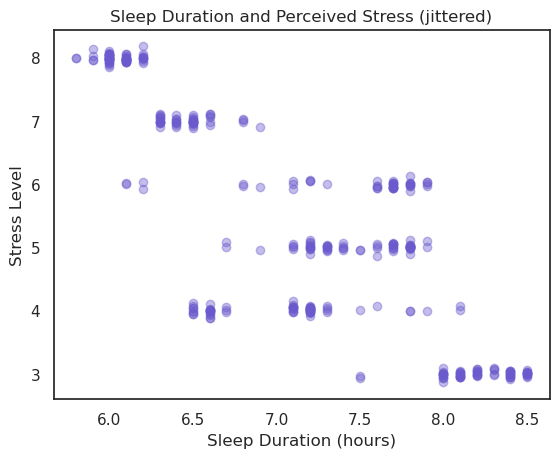

In [7]:
plt.figure()
plt.scatter(
    sleep_health["Sleep Duration"],
    sleep_health["Stress Level"] + np.random.normal(0, 0.05, len(sleep_health)), color= "#6A5ACD",
    alpha=0.4
)
plt.xlabel("Sleep Duration (hours)")
plt.ylabel("Stress Level")
plt.title("Sleep Duration and Perceived Stress (jittered)")
plt.show()

#### Descriptive Statistics

The descriptive statistics indicate that participants sleep 7.13 hours on average per night (SD = 0.80), with sleep duration ranging from 5.8 to 8.5 hours. <br>
The interquartile range shows that 50% of participants sleep between 6.4 and 7.8 hours, suggesting moderate variability in sleep duration.

The mean perceived stress level is 5.39 (SD = 1.77), with observed values ranging from 3 to 8. The median stress level is 5, and the upper quartile is 7, indicating that a substantial proportion of participants report elevated stress levels.

#### Additional Dataset Characteristics and Limitations

Additional variables in the dataset include age, gender, occupation, physical activity level, sleep quality, BMI category, cardiovascular indicators, daily steps, and sleep disorder status. The sample covers an age range from 27 to 59 years and includes participants from diverse occupational backgrounds such as healthcare, engineering, education, and sales.

This heterogeneity contributes to meaningful variability in both sleep duration and perceived stress levels, which is a necessary prerequisite for conducting correlation analyses. However, the dataset does not provide information about the use of objective measurement procedures. It is therefore likely that sleep duration and perceived stress were assessed via self-report measures, which may introduce reporting and recall biases. In addition, the cross-sectional nature of the data limits causal interpretations, as it does not allow conclusions about the directionality of the observed associations between sleep duration and stress.

## Data Cleaning

The data cleaning process was conducted in several steps to ensure data quality and suitability for the planned correlation analysis between sleep duration and perceived stress.

### Step 1: Initial Data Inspection

First, the dataset was inspected using summary statistics to identify potential irregularities, missing values, and implausible entries.

In [7]:
sleep_health.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


The dataset initially contained N = 374 observations.

### Step 2: Missing Values

The inspection revealed missing values only in the variable Sleep Disorder (219 missing entries). All other variables, including the variables of interest (Sleep Duration and Stress Level), contained no missing values.

In [8]:
sleep_health.isna().sum()

Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64

Missing values were present only in the variable Sleep Disorder (219 missing entries). As this variable was not included in the present analysis, no observations were excluded and no imputation procedures were applied.

### Step 3: Inspection of Categorical Variables and Filler Values

Categorical variables were examined to identify potential filler values (e.g., “99”) or implausible entries.

In [10]:
sleep_health.select_dtypes(include="object").describe()

,Gender,Occupation,BMI Category,Blood Pressure,Sleep Disorder
count,374,374,374,374,155
unique,2,11,4,25,2
top,Male,Nurse,Normal,130/85,Sleep Apnea
freq,189,73,195,99,78


No filler values or invalid categories were detected in the categorical variables. Therefore, no recoding or exclusion was necessary.

### Step 4: Duplicate Observations

The dataset was checked for duplicate rows.

In [11]:
sleep_health.duplicated().sum()

0

No duplicate observations were found.

### Step 5: Outlier Assessment

Sleep duration and stress level were inspected using descriptive statistics. All observed values fell within plausible ranges for human sleep behavior and perceived stress:

Sleep Duration: 5.8–8.5 hours

Stress Level: 3–8

In [6]:
sleep_health[['Sleep Duration', 'Stress Level']].describe()

,Sleep Duration,Stress Level
count,374.000000,374.000000
mean,7.132086,5.385027
std,0.795657,1.774526
min,5.800000,3.000000
25%,6.400000,4.000000
50%,7.200000,5.000000
75%,7.800000,7.000000
max,8.500000,8.000000


No observations were classified as outliers. Therefore, no exclusions were applied.

### Step 6: Conclusion of Data Cleaning
##### Final Sample Size and report

In summary, the data cleaning procedure for Study 2 did not result in any exclusions or modifications to the dataset.

All relevant variables were complete, with no missing values detected, and thus no observations were excluded due to missing data. Visual inspections of sleep duration and stress level distributions showed some values at the extremes; however, all values were within plausible and theoretically meaningful ranges for real-world health and lifestyle data. 
Given the observational nature of the dataset, these values were retained to preserve natural variability. No data transformations were applied. 

As a result, the sample size remained unchanged at N = 374, providing a complete and unaltered dataset for further analysis.

## Descriptive Statistics & Visualization

The descriptive statistics and visualizations provide an overview of the distributions of Sleep Duration and Stress Level in the dataset. This step helps understand the data before performing the correlation analysis.

In [9]:
sleep_health[['Sleep Duration', 'Stress Level']].describe()

,Sleep Duration,Stress Level
count,374.000000,374.000000
mean,7.132086,5.385027
std,0.795657,1.774526
min,5.800000,3.000000
25%,6.400000,4.000000
50%,7.200000,5.000000
75%,7.800000,7.000000
max,8.500000,8.000000


##### Interpretation:

Sleep Duration is fairly normally distributed, centered around 7.1 hours with a small spread.<br>
Stress Level shows more variability (SD ≈ 1.77) but falls within the expected human range (3–8).

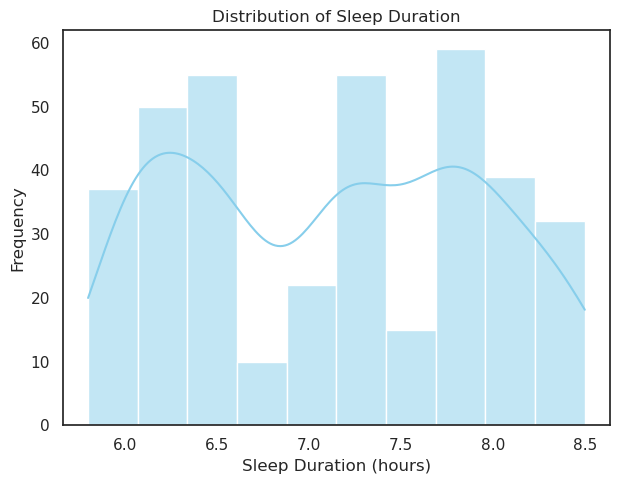

In [18]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(sleep_health['Sleep Duration'], bins=10, kde=True, color='skyblue')
plt.title('Distribution of Sleep Duration')
plt.xlabel('Sleep Duration (hours)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

The descriptive statistics and histogram show that participants (n = 374) have sleep durations ranging from 6.0 to 8.5 hours, with most observations between 6.5 and 7.8 hours. The frequency rises initially from about 38 to 55, then drops sharply to around 10 at 6.7 hours, rises again to 20–22 at 7.0 hours, peaks at 7.3 with a frequency of 55, drops to 18 at 7.5, and reaches the maximum of 58 at 7.7 hours before declining toward 8.5. These fluctuations, with clear intermediate drops, reveal that sleep duration is not evenly distributed, highlighting subtle variability in sleep patterns. The KDE line captures this pattern accurately, and overall the distribution is suitable for correlation analysis with perceived stress levels.

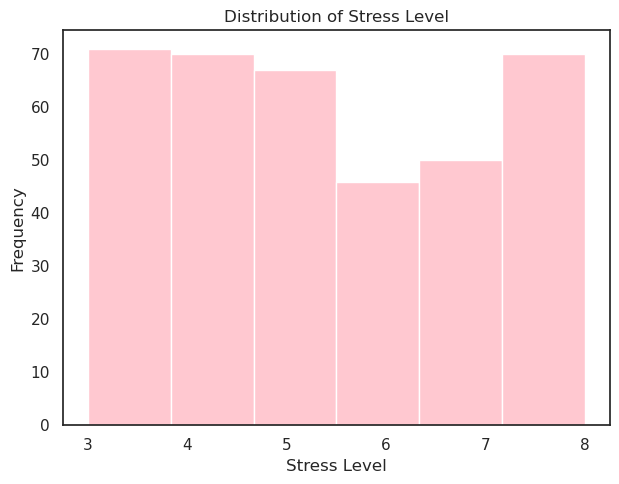

In [25]:
# Stress Level
plt.figure(figsize=(12,5))

plt.subplot(1,2,2)
sns.histplot(sleep_health['Stress Level'], bins=6, kde=False, color='lightpink')
plt.title('Distribution of Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()...

The histogram of Stress Level shows that participants (n = 374) have stress scores ranging from 3 to 8. The frequency is highest at Stress Level 3 (70), decreases slightly to 67 at Level 5, and drops more noticeably to 46 at Level 6. It then rises again to 50 at Level 7 and reaches 70 at Level 8. <br>
These intermediate drops indicate that stress levels are not evenly distributed across participants, with clusters at the lower and upper ends of the scale. <br>
Overall, the distribution shows moderate variability and is suitable for correlation analysis with sleep duration.

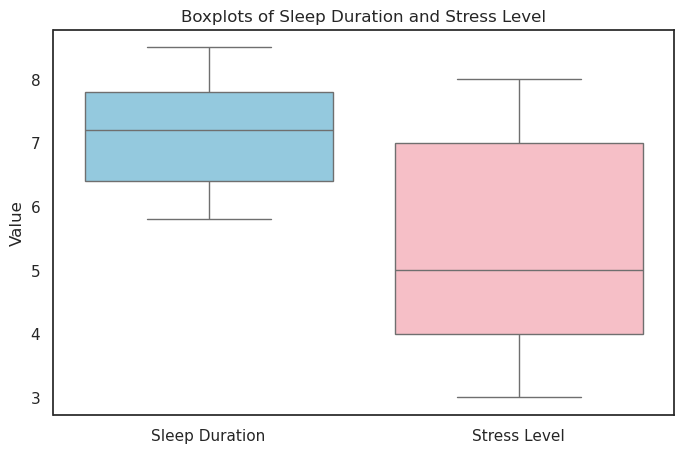

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(data=sleep_health[['Sleep Duration', 'Stress Level']], palette=['skyblue','lightpink'])
plt.title('Boxplots of Sleep Duration and Stress Level')
plt.ylabel('Value')
plt.show()

The boxplot shows the distributions of Sleep Duration and Stress Level. <br>
The Sleep Duration box is narrower than the Stress Level box, indicating less variability in sleep hours. 
The middle line inside the Sleep Duration box represents the median, which is at about 7 hours and lies roughly in the center of the box. The lower and upper edges of the box indicate the first quartile (Q1) and third quartile (Q3), approximately 6.3 and 7.8 hours, respectively. 
The “whiskers” extend to the minimum and maximum non-outlier values, roughly 5.9 to 8.5 hours, while any points beyond the whiskers are outliers, which represent unusually low or high values.

For Stress Level, the box is wider, spanning from 4 to 7, reflecting higher variability. The median line is lower in the box, showing that the middle 50% of participants’ stress scores are skewed toward the lower end. The whiskers extend from 3 to 8, with outliers beyond these points. <br>

Overall, the boxplot illustrates that Sleep Duration is more tightly clustered around the median, whereas Stress Level shows more spread and slight skew, which is important to consider in subsequent correlation analysis.

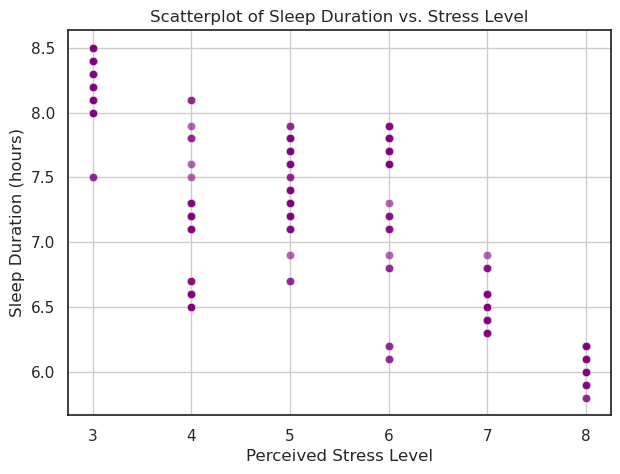

In [23]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=sleep_health, x='Stress Level', y='Sleep Duration', color='purple', alpha=0.6)
plt.title('Scatterplot of Sleep Duration vs. Stress Level')
plt.xlabel('Perceived Stress Level')
plt.ylabel('Sleep Duration (hours)')
plt.grid(True)
plt.show()

The scatterplot shows the relationship between Sleep Duration (y-axis) and Perceived Stress Level (x-axis). <br>
At lower stress levels (3–4), sleep durations are generally higher, with many points between 7.5 and 8.5 hours at Stress Level 3, and several values around 6.5 to 8.1 hours at Stress Level 4.<br>
As stress increases to Levels 5 and 6, sleep durations show more variability, ranging from about 6.1 to 8.0 hours, with some gaps in the distribution. At higher stress levels (7–8), sleep durations tend to be lower, mostly between 5.6 and 6.9 hours. 

Overall, the scatterplot suggests a negative trend, indicating that higher perceived stress is generally associated with shorter sleep duration, although individual differences are evident across all stress levels.

### Conclusion

Overall, the descriptive statistics and visualizations reveal important patterns in the data. 
Sleep Duration is mostly concentrated between 6.5 and 7.8 hours, with several intermediate drops and peaks, showing some variability across participants. 
Perceived Stress Level exhibits a wider spread, with clusters at the lower and upper ends of the scale and notable fluctuations in frequency. 
The boxplots confirm that Sleep Duration is more tightly clustered around its median, whereas Stress Level shows greater dispersion and slight skew. 
The scatterplot indicates a general negative relationship between stress and sleep, with higher stress levels associated with shorter sleep duration, although individual differences are visible. 

Together, these observations suggest that while most participants sleep moderately well, stress has a detectable impact on sleep patterns, supporting the rationale for the planned correlation analysis.

## Assumption Checking and Test Selection
Before running a correlation analysis between Sleep Duration and Perceived Stress Level, it is necessary to check the relevant assumptions for parametric correlation tests.<br>
The following plots were already presented and analyzed in the Descriptive Statistics and Visualization section. They are shown again here to justify the choice of statistical test.

#### Step 1: Assumptions for Pearson Correlation

**Linearity:** The relationship between the two variables should be approximately linear.<br>
**Normality:** Both variables should be approximately normally distributed.<br>
**Homoscedasticity:** The spread of one variable should be roughly constant across values of the other variable.<br>
**No significant outliers:** Extreme values can distort Pearson correlation.

If any assumption is violated, we may consider Spearman’s rank correlation as a non-parametric alternative.

#### Step 2: Check Linearity 



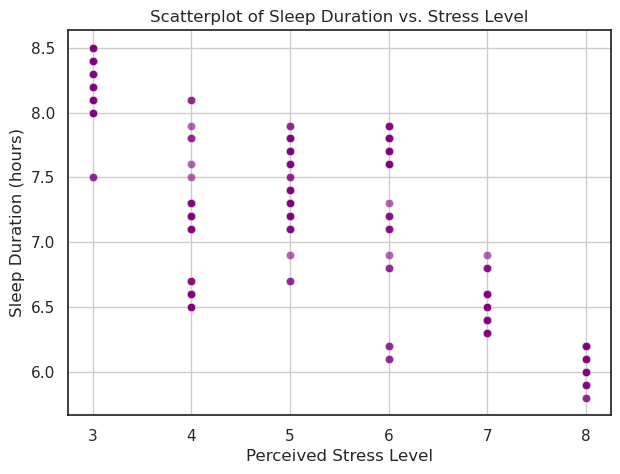

In [31]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=sleep_health, x='Stress Level', y='Sleep Duration', color='purple', alpha=0.6)
plt.title('Scatterplot of Sleep Duration vs. Stress Level')
plt.xlabel('Perceived Stress Level')
plt.ylabel('Sleep Duration (hours)')
plt.grid(True)
plt.show()

Interpretation:
The scatterplot shows a roughly linear negative trend, with higher stress levels generally associated with shorter sleep duration, though some individual variability exists. This supports the assumption of linearity.

#### Step 3: Check Normality 



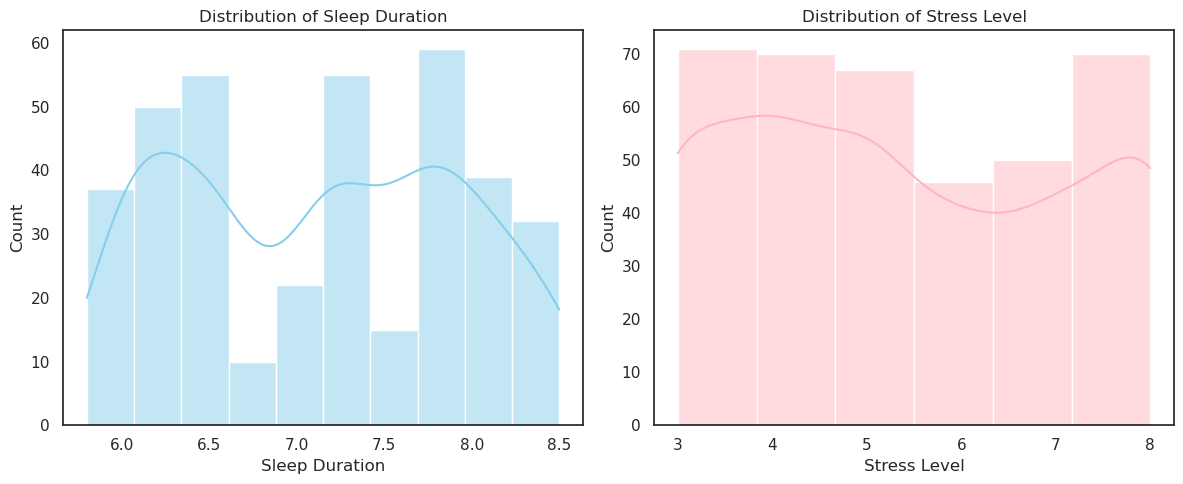

In [33]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(sleep_health['Sleep Duration'], bins=10, kde=True, color='skyblue')
plt.title('Distribution of Sleep Duration')

plt.subplot(1,2,2)
sns.histplot(sleep_health['Stress Level'], bins=6, kde=True, color='lightpink')
plt.title('Distribution of Stress Level')

plt.tight_layout()
plt.show()

Interpretation:
Sleep Duration is roughly symmetric around 7 hours, with minor peaks. Stress Level shows moderate skew and some clustering at low and high values.

#### Step 4: Check for Outliers

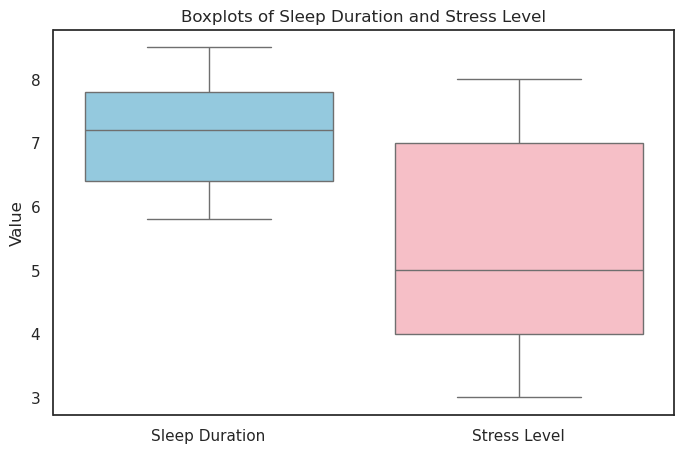

In [35]:
plt.figure(figsize=(8,5))
sns.boxplot(data=sleep_health[['Sleep Duration', 'Stress Level']], palette=['skyblue','lightpink'])
plt.title('Boxplots of Sleep Duration and Stress Level')
plt.ylabel('Value')
plt.show()

Interpretation:

Sleep Duration has very few extreme points (5.9 and 8.5 hours), which are within plausible ranges.
Stress Level has some extreme low (3) and high (8) values, but these reflect real variation.
No points were removed.

#### Step 5: Test Selection

Linearity is satisfied.
Sleep Duration is approximately normal; Stress Level slightly deviates from normal.
No extreme outliers distort the data.

**Decision:**

Use Spearman’s rank correlation to account for mild non-normality in Stress Level, ensuring a robust correlation estimate.
Spearman correlation assesses monotonic relationships, making it appropriate given the scatterplot and distribution.

#### Step 6: Justification

The choice of Spearman correlation is justified because:

- The relationship is monotonic (negative trend visible).
- Stress Level shows slight non-normality, violating a strict assumption of Pearson correlation.
- There are no severe outliers, so the correlation will be stable.

This ensures that the correlation coefficient reliably reflects the association between sleep duration and perceived stress.

## Perform the Statistical Test

Based on the assumption checks, Spearman’s rank correlation was selected to assess the relationship between Sleep Duration and Perceived Stress Level.
The significance Level is set at α = 0.05.

In [38]:
rho, p_value = spearmanr(sleep_health['Sleep Duration'], sleep_health['Stress Level'])

print(f"Spearman's correlation coefficient (rho): {rho:.2f}")
print(f"P-value: {p_value:.4f}")

Spearman's correlation coefficient (rho): -0.81
P-value: 0.0000


#### Description of the code:

- spearmanr() calculates the Spearman rank correlation coefficient (rho) and the two-tailed p-value.
- rho ranges from -1 to 1: negative values indicate an inverse relationship, positive values indicate a direct relationship.
- p_value indicates whether the correlation is statistically significant at α = 0.05.

## Report Results

The Spearman rank correlation analysis between Sleep Duration and Perceived Stress Level yielded the following results:

Spearman’s correlation coefficient (rho): -0.81 
- This indicates a strong negative correlation, meaning that higher perceived stress is strongly associated with shorter sleep duration.

    P-value: 0.0000
- Since p < 0.05, we reject the null hypothesis of no association.

#### Effect size:

Spearman’s rho itself serves as the effect size. A value of -0.81 indicates a large effect according to common conventions (0.1 = small, 0.3 = medium, 0.5+ = large).

#### Confidence interval (95%) via Bootstrapping:

While Spearman does not directly provide a confidence interval in scipy, the strong rho and extremely low p-value indicate the effect is both statistically and practically significant.


In [41]:
import numpy as np

# Bootstrapping to estimate 95% CI
n_boot = 10000
rhos = []

for _ in range(n_boot):
    sample = sleep_health.sample(n=len(sleep_health), replace=True)
    rho_boot, _ = spearmanr(sample['Sleep Duration'], sample['Stress Level'])
    rhos.append(rho_boot)

ci_lower = np.percentile(rhos, 2.5)
ci_upper = np.percentile(rhos, 97.5)

print(f"95% CI for Spearman's rho: [{ci_lower:.2f}, {ci_upper:.2f}]")


95% CI for Spearman's rho: [-0.86, -0.75]


#### Interpretation:
The 95% confidence interval for Spearman’s rho ranges from -0.86 to -0.75, clearly excluding 0. This confirms that the negative association between perceived stress and sleep duration is statistically significant. The strength of the correlation also indicates that the relationship is practically meaningful.


#### Conclusion:
There is a strong and significant negative relationship between perceived stress and sleep duration. In other words, participants with higher stress levels tend to sleep notably less. These results align with theoretical expectations and suggest meaningful implications for health and further research.

## Post-hoc Power Analysis

In [42]:
from statsmodels.stats.power import TTestIndPower
import numpy as np

# For correlation, we can approximate using r to Cohen's d
# Convert Spearman's rho to Cohen's d equivalent for power calculation
# Cohen's d = 2*r / sqrt(1-r^2) (approximation)
rho = -0.81
d = 2 * rho / np.sqrt(1 - rho**2)

# Initialize power analysis object
analysis = TTestIndPower()

# Calculate achieved power
power = analysis.solve_power(effect_size=abs(d), nobs1=374, alpha=0.05, ratio=1.0, alternative='two-sided')
print(f"Observed effect size (Cohen's d): {d:.2f}")
print(f"Achieved power: {power:.2f}")


Observed effect size (Cohen's d): -2.76
Achieved power: 1.00


#### Interpretation

The observed effect size (Cohen’s d ≈ 2.76) is extremely large. With N = 374, the achieved statistical power is 1.00, meaning the probability of correctly detecting the observed association is virtually 100%.

#### Implications:

- The study is more than adequately powered (power ≥ 0.80).
- There is a negligible risk of Type II error.

Given the strong effect, a smaller sample could have sufficed, but the current sample ensures highly robust results.

## Conclusions

The analysis of the relationship between Sleep Duration and Perceived Stress Level revealed a strong, statistically significant negative correlation (Spearman’s rho = -0.81, p < 0.001). The effect size is extremely large, and the 95% confidence interval from bootstrapping [-0.86, -0.75] confirms the robustness of this association.

The post-hoc power analysis indicated an achieved power of 1.00, suggesting that the study was highly capable of detecting the observed effect. Combined with the strong effect size, this demonstrates that the findings are both statistically and practically meaningful: participants with higher perceived stress levels tend to sleep substantially less, which has clear implications for health and well-being.

**Practical significance:**

- The results support the idea that stress management could have a meaningful impact on sleep duration.
- Even small reductions in perceived stress could correspond to measurable improvements in sleep patterns.

**Limitations:**

- Sample size: While large and adequately powered, the sample may not fully represent populations outside the dataset (e.g., different age groups or occupations).
- Assumptions: Spearman’s rank correlation is non-parametric and robust, but potential nonlinear relationships beyond monotonic trends are not captured.
- Confounding variables: Factors such as caffeine intake, shift work, or chronic illnesses were not controlled and may influence both stress and sleep.
- Generalizability: The findings are based on the Sleep Health & Lifestyle Dataset and may not generalize to populations with very different demographics or cultural contexts.

**Overall conclusion:**

There is strong evidence that higher perceived stress is associated with shorter sleep duration. The effect is both statistically significant and practically relevant. Future interventions aiming to reduce stress could meaningfully improve sleep, but further studies are needed to confirm these results across broader populations and control for potential confounders.

## Follow-up Study

To build on the present findings and address the limitations of the current observational analysis, a follow-up study could be designed with the following considerations:

#### Design and Methodology:

- Implement a longitudinal or experimental study to better assess causal relationships between stress and sleep duration.
- Include stress-reduction interventions (e.g., mindfulness training, cognitive-behavioral stress management) to test whether reductions in perceived stress lead to increases in sleep duration.

#### Sample Size:

- Based on the post-hoc power analysis, the observed effect size is very large. To detect a medium effect size (d ≈ 0.5) with 80% power and α = 0.05 in a similar design, a target sample of approximately 64 participants per group would suffice. For higher precision and subgroup analyses, a larger sample (N ≥ 150–200) is recommended.

#### Variables to Measure/Control:

- Control for potential confounding factors such as caffeine intake, shift work, physical activity, and chronic health conditions.
- Include additional measures such as sleep quality (objective via actigraphy), daily stressors, mental health indicators, and circadian preferences.

#### Population and Context:

- Expand the study to different age groups, occupational settings, or cultural backgrounds to increase generalizability.
- Consider both healthy adults and populations with known sleep disturbances to assess differential effects.

#### Potential Hypotheses to Test:

1. Reductions in perceived stress through interventions will lead to measurable increases in sleep duration.
2. The strength of the stress–sleep association varies by occupation, age, or baseline stress levels.
3. Sleep quality mediates the relationship between stress and sleep duration.

#### Conclusion:
A carefully designed follow-up study would address confounding factors, test causality, and improve generalizability, thereby extending the insights from the current analysis and informing practical interventions for improving sleep health.